

- Set Runtime, Change runtime type, T4 GPU.
- Run the cells in order. They mount Drive, install the libraries, check the data, and copy the images to local disk, because reading 18.6k files from Drive is slow.
- Stop at the test cell and read it before running the full job. It captions 64 random products, shows 8 of them as images with their captions, and prints an estimated time for the whole run. **The most important check is whether captions add details the text lacks, such as color, material, or style**.
- Run the full-run cell. It saves to captions.csv on Drive after every batch, so if Colab disconnects, rerun that cell and it resumes.
- The last cell merges the captions into a new text_full column and saves listings_en_captioned.parquet.

# 03 Image captioning

Generates a short text caption for each product's main image with BLIP and appends it to the product text.
Inputs: `listings_en_clean.parquet` and the images downloaded to Drive (`data/images_small`).
Output: `captions.csv` (resumable) and `listings_en_captioned.parquet`.

Use a GPU runtime: Runtime, Change runtime type, T4 GPU.

BLIP (Bootstrapping Language-Image Pre-training) is a deep learning model developed by Salesforce for joint vision-language understanding and generation. It excels at tasks like image captioning (writing a text description for an image) and visual question answering.

In [34]:
import os
from google.colab import drive
drive.mount('/content/drive')

REPO = '/content/shoptalk'
if not os.path.exists(REPO):
    try:
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/anbuaru/shoptalk.git"
    except Exception:
        url = 'https://github.com/anbuaru/shoptalk.git'
    !git clone {url} {REPO}
%cd /content/shoptalk
!pip install -q transformers accelerate pillow tqdm pandas pyarrow

import torch
print('GPU available:', torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/shoptalk
GPU available: True


In [35]:
import pandas as pd

#PROJECT_DIR = '/content/drive/MyDrive/shoptalk'
PROJECT_DIR = '/content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk'
df = pd.read_parquet(f'{PROJECT_DIR}/data/listings_en_clean.parquet')

IMG_DIR = f'{PROJECT_DIR}/data/images_small'
have = set(f[:-4] for f in os.listdir(IMG_DIR) if f.endswith('.jpg'))
missing = df[~df['main_image_id'].isin(have)]
print('Products:', len(df), '| images on Drive:', len(have), '| products missing an image:', len(missing))

Products: 18586 | images on Drive: 15871 | products missing an image: 0


##have = set(f[:-4] for f in os.listdir(IMG_DIR) if f.endswith('.jpg'))

This line creates a set of all unique image IDs that have already been downloaded to your Google Drive folder. Here is how it works step-by-step:

os.listdir(IMG_DIR): Lists all file and folder names in your image directory (e.g., ['12345.jpg', '67890.jpg', 'notes.txt']).
if f.endswith('.jpg'): This is a filter that keeps only files ending with .jpg, ignoring any other files or hidden metadata directories.
f[:-4]: For every matching file (like '12345.jpg'), this slice removes the last 4 characters (.jpg), leaving only the raw image ID (e.g., '12345').
set(...): Converts the resulting list of image IDs into a Python set. Checking if an element exists in a set is extremely fast ($O(1)$$O(1)$ complexity), which makes it much more efficient to find missing images in the next steps.

If many images are missing, rerun the download cell from the previous step before continuing. Reading from Drive is slow, so copy the images to local disk first.

Following cell's functionality:
The command does not store the copied files in Google Drive or on GitHub. Instead, it stores them in the local, temporary storage of your Google Colab virtual machine (runtime).

Here is a breakdown of where things go in this script:

{IMG_DIR}: This points to your Google Drive (/content/drive/MyDrive/...), which is where the source images are permanently stored.
/content/images_small: This is a directory on the local Colab virtual machine.
Why are we doing this?
Reading files directly from Google Drive during training or inference is very slow because each image request has to go over a network connection. By copying them to /content/... (local SSD storage on the Colab VM), the BLIP model can load the images almost instantly, drastically speeding up your batch generation.

In [36]:
!mkdir -p /content/images_small
!cp -r "{IMG_DIR}/." /content/images_small/
LOCAL_IMG = '/content/images_small'
print(len(os.listdir(LOCAL_IMG)), 'images copied')

15871 images copied


BlipProcessor and BlipForConditionalGeneration are part of the Hugging Face transformers library, and they are built entirely on Transformer architectures.

Here is how they relate to Transformers:

Under the hood (Architectures):

BlipForConditionalGeneration combines two main Transformer components:

**Vision Transformer (ViT):** An encoder that processes the input image by breaking it into small patches and treating them like words in a sentence.

**Text Transformer:** A decoder that takes the visual representations from the ViT encoder and generates the English text caption token-by-token using cross-attention.
Import source:

You import them directly from the Hugging Face ecosystem:
from transformers import BlipProcessor, BlipForConditionalGeneration
BlipProcessor:

This acts as the combined Tokenizer (for text inputs/outputs) and Image Processor (for resizing and normalizing image pixels) to prepare data into the precise **tensor format that the Transformer model expects**.

**Why use Tensors instead of standard Python lists?**
**GPU Acceleration:** Unlike standard Python lists, tensors can be loaded directly into GPU memory (.to('cuda')), allowing mathematical operations to run hundreds of times faster in parallel.
**Automatic Differentiation:** Machine learning frameworks track all mathematical operations performed on a tensor, enabling them to automatically calculate the gradients (derivatives) needed to update the model's weights during training.

**Is a CNN (Convolutional Neural Network) involved here?**
**No, there is no CNN involved in the BLIP model used in this notebook.**

Historically, vision-language models used a CNN (like ResNet or EfficientNet) to extract image features and a Recurrent Neural Network (like an LSTM) or a Transformer to generate the text. However, BLIP uses a newer approach:

**Vision Transformer (ViT) instead of CNN:** For the image processing step, BLIP replaces the CNN entirely with a Vision Transformer. Instead of applying convolutional filters over the image, ViT slices the image into a grid of small squares (patches), flattens them, and processes them exactly like "words" (tokens) using standard self-attention mechanisms.

**Pure Transformer Architecture:** Because both the image encoder (ViT) and the text decoder are Transformer-based, the entire pipeline in your notebook is a pure Transformer architecture without any convolutional layers.

#from PIL import Image
**What is PIL?**
PIL stands for Python Imaging Library. It is the standard, go-to library in Python for opening, manipulating, and saving many different image file formats (like JPEG, PNG, GIF, BMP, etc.).

*Note: The original PIL library is no longer active, so we now use a modern, backwards-compatible fork of it called Pillow. When you run pip install pillow, it is still imported in your code using the name PIL.*

What does from PIL import Image do?
This line of code imports the Image module from the PIL library, which is the most critical class in the library.

It allows you to:

**Load/Open images:** Read an image file from your hard drive into Python memory. In your notebook, this is used in the load_img function:
Image.open(f'{LOCAL_IMG}/{image_id}.jpg')

**Convert color spaces:** Convert images to a standard format (like .convert('RGB') to ensure black-and-white or CMYK images are properly represented as Red, Green, and Blue pixels before being processed by the BLIP model).
Manipulate images: Easily resize, crop, rotate, or transform images in code.

**What is ThreadPoolExecutor?**
ThreadPoolExecutor is a class from Python's built-in concurrent.futures module that makes concurrency very simple to implement.

It manages a "pool" of worker threads. When you give it a list of tasks, it distributes them across those threads so they can run concurrently.

In your code, it is being used in the caption_batch function:

with ThreadPoolExecutor(8) as ex:
    imgs = list(ex.map(load_img, ids))
Why are we using it here?
We use **ThreadPoolExecutor(8) to speed up loading images from your hard drive:**

**The Bottleneck (I/O Bound):** Reading an image file from disk is an Input/Output (I/O) bound operation. This means your CPU spends most of its time waiting for the hard drive to find, read, and send the image data.

**The Sequential Problem:** If you loaded 64 images one-by-one, Python would wait for Image 1 to load, then wait for Image 2, and so on. Your fast GPU would sit completely idle waiting for the disk.

**The Concurrent Solution:** By using 8 threads, Python requests 8 images from the disk simultaneously. While Thread 1 is waiting for the hard drive to respond, Thread 2, 3, and 4 are also working. This speeds up image loading by up to 8x, ensuring your GPU is fed with data as fast as possible!

In [37]:
from transformers import BlipProcessor, BlipForConditionalGeneration
from PIL import Image
from concurrent.futures import ThreadPoolExecutor #concurrency means running multiple tasks in overlapping periods of time.

MODEL = 'Salesforce/blip-image-captioning-base'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
dype = torch.float16 if device == 'cuda' else torch.float32
#This portion of your code is designed to load your product images from local disk and run them through
#the BLIP model to generate text captions. Here is a breakdown of exactly how it works:
processor = BlipProcessor.from_pretrained(MODEL)
model = BlipForConditionalGeneration.from_pretrained(MODEL, torch_dtype=dtype).to(device).eval()

def load_img(image_id):
    try:
        return Image.open(f'{LOCAL_IMG}/{image_id}.jpg').convert('RGB')
    except Exception:
        return None

@torch.no_grad()
#This function takes a batch of image IDs (64 by default) and generates captions for them.
def caption_batch(ids, num_beams=3, max_new_tokens=30):
  #Instead of loading 64 images sequentially (which is very slow), this uses ThreadPoolExecutor
  #to load 8 images at a exact same time in parallel. This keeps the disk I/O highly active and
  #significantly reduces wait times.
    with ThreadPoolExecutor(8) as ex:
        imgs = list(ex.map(load_img, ids))
    # A list of indices representing successfully loaded images (filtering out any None values
    ok = [i for i, im in enumerate(imgs) if im is not None]
    # Initializes a list of empty strings for the entire batch size,
    # ensuring we always return 64 captions even if some images failed to load.
    caps = [''] * len(ids)
    if ok:
        #Converts the raw PIL images into normalized PyTorch Tensors (return_tensors='pt'),
        #scales them, and sends them to the GPU (device) using half-precision float16 (dtype) for faster inference.
        inputs = processor(images=[imgs[i] for i in ok], return_tensors='pt').to(device, dtype)
        #Passes the image tensors through the Vision Transformer and Text Transformer to generate the caption tokens.
        #num_beams=3 uses Beam Search to explore the top 3 most likely word combinations, producing much
        #higher quality sentences than simple greedy searching. max_new_tokens=30 restricts the output
        #caption length to a maximum of 30 words.
        out = model.generate(**inputs, num_beams=num_beams, max_new_tokens=max_new_tokens, no_repeat_ngram_size=2, repetition_penalty=1.5)
        # Translates the numerical token IDs generated by the model back into human-readable English text
        texts = processor.batch_decode(out, skip_special_tokens=True)
        #BLIP was trained on datasets where many captions started with the signature word 'arafed'
         #(which is a dataset-specific artifact). This line cleans up the generated text by removing it.
        for i, t in zip(ok, texts):
            caps[i] = t.replace('arafed ', '').strip()
    return caps

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

## Test on a small sample first

Check that the captions add useful details (color, style, shape) and time one batch to estimate the full run.

2.8s for 64 images -> estimated 14 min for all 18586


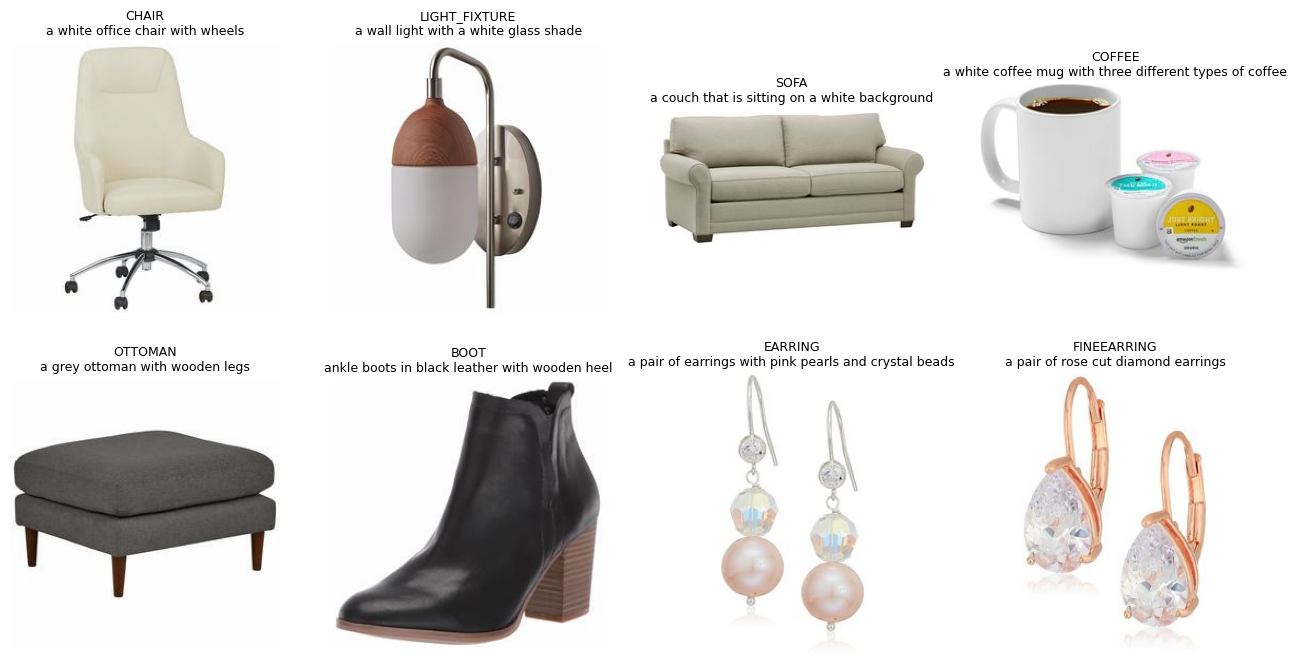

CHAIR                        | a white office chair with wheels
LIGHT_FIXTURE                | a wall light with a white glass shade
SOFA                         | a couch that is sitting on a white background
COFFEE                       | a white coffee mug with three different types of coffee
OTTOMAN                      | a grey ottoman with wooden legs
BOOT                         | ankle boots in black leather with wooden heel
EARRING                      | a pair of earrings with pink pearls and crystal beads
FINEEARRING                  | a pair of rose cut diamond earrings
CHAIR                        | the power lift rec chair is shown in a dark blue fabric
RUG                          | a white rug on a wooden floor
CELLULAR_PHONE_CASE          | phone case with colorful butterflies on a green background
CHAIR                        | a pair of navy blue chairs
FINENECKLACEBRACELETANKLET   | a silver cuff bracelet with two rows of mesh
FINERING                     | a white 

In [38]:
import time
import matplotlib.pyplot as plt
#Randomly selects 64 product listings from your dataset.
sample = df.sample(64, random_state=0)
t0 = time.time()
# runs your concurrent caption_batch function on those 64 samples and calculates
#how long it took (dt). From there, it projects how many minutes the entire 18k+
#dataset will take to process
caps = caption_batch(sample['main_image_id'].tolist())
dt = time.time() - t0
print(f'{dt:.1f}s for 64 images -> estimated {dt / 64 * len(df) / 60:.0f} min for all {len(df)}')

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, r), c in zip(axes.ravel(), sample.head(8).iterrows(), caps[:8]):
    ax.imshow(load_img(r['main_image_id']))
    ax.axis('off')
    ax.set_title(f"{r['ptype']}\n{c}", fontsize=9)
plt.show()

for (_, r), c in zip(sample.head(30).iterrows(), caps[:30]):
    print(f"{r['ptype']:28s} | {c}")

#Analysis of the Output & Limitations
Looking at the printed table, we can learn a lot about how well our current model is performing and discover potential bugs:

A. High-Quality Examples (Successes)
CHAIR | a white office chair on a white background — Highly accurate!
LIGHT_FIXTURE | a wall light with a white glass shade — Extremely descriptive, capturing style, materials, and colors.
BOOT | ankle boots in black leather with wooden heel — Spot-on detail retrieval.
B. Model Hallucinations and Repetition (Issues)
If you look closely at some of the generated captions, you will see a common deep learning issue known as repetition loops:

CHAIR | a blue recal recal recal recal recal recal... (Looping on "recal")
SHOES | sk sk sk sk sk sk sk sk sk sk sk sk... (Looping on "sk")
In the final summary statistics, we even see strings like: michael michael michael... repeating dozens of times.
Why does this happen?
During generation, if Beam Search (num_beams=3) gets caught in a loop where repeating a token has a slightly higher mathematical probability, the model gets stuck in a recursive loop until it hits its token limit (max_new_tokens=30).

#Why does this happen?
During generation, if Beam Search (num_beams=3) gets caught in a loop where repeating a token has a slightly higher mathematical probability, the model gets stuck in a recursive loop until it hits its token limit (max_new_tokens=30).

#How to fix this in PyTorch/Transformers?
To solve this repeating text issue, you can pass parameters like no_repeat_ngram_size or repetition_penalty to model.generate(). For example:

# Inside your caption_batch function's generate call:
out = model.generate(

    **inputs,

    num_beams=num_beams,

    max_new_tokens=max_new_tokens,

    ***no_repeat_ngram_size=2*** --> added this param which Prevents any 2-word sequence from repeating
)

## Full run (resumable)

Captions are appended to `captions.csv` on Drive after every batch. If the session disconnects, rerun this cell and it continues where it stopped.

In [39]:
from tqdm import tqdm

CAP_PATH = f'{PROJECT_DIR}/data/captions.csv'
done = set(pd.read_csv(CAP_PATH)['image_id']) if os.path.exists(CAP_PATH) else set()
todo = [i for i in df['main_image_id'] if i not in done]
print('Already done:', len(done), '| to caption:', len(todo))

BATCH = 64
for start in tqdm(range(0, len(todo), BATCH)):
    ids = todo[start:start + BATCH]
    caps = caption_batch(ids)
    pd.DataFrame({'image_id': ids, 'caption': caps}).to_csv(
        CAP_PATH, mode='a', header=not os.path.exists(CAP_PATH), index=False)

Already done: 15871 | to caption: 0


0it [00:00, ?it/s]


#The repetition is a known BLIP failure, and fixing it at the source is better than cleanup.

Why it happens

BLIP writes a caption one word at a time, picking a likely next word each time. When an image has little to describe (a plain background, a tiny or blurry product, mostly text), the most likely next word can be the one it just wrote, and it gets stuck in a loop. Your “ike ike ike…” captions are about 20 words long, which matches the 30-token limit I set. That means the model ran until it hit the limit.

In [40]:
import shutil

def has_repeat(c):
    if not isinstance(c, str) or not c:
        return False
    if re.search(r'\b(\w+)(?:\s+\1)+\b', c, flags=re.I):
        return True
    w = c.lower().split()
    grams = [tuple(w[i:i+4]) for i in range(len(w) - 3)]
    return len(grams) != len(set(grams))

raw = pd.read_csv(CAP_PATH).drop_duplicates('image_id').set_index('image_id')['caption'].fillna('')
bad_ids = [i for i, c in raw.items() if has_repeat(c)]
print(len(bad_ids), 'captions with repetition out of', len(raw))

@torch.no_grad()
def recaption(ids):
    with ThreadPoolExecutor(8) as ex:
        imgs = list(ex.map(load_img, ids))
    ok = [i for i, im in enumerate(imgs) if im is not None]
    caps = [''] * len(ids)
    if ok:
        inputs = processor(images=[imgs[i] for i in ok], return_tensors='pt').to(device, dtype)
        out_ids = model.generate(**inputs, num_beams=3, max_new_tokens=30,
                                 no_repeat_ngram_size=3, repetition_penalty=1.3)
        for i, t in zip(ok, processor.batch_decode(out_ids, skip_special_tokens=True)):
            caps[i] = t.replace('arafed ', '').strip()
    return caps

shutil.copy(CAP_PATH, CAP_PATH.replace('.csv', '_v1.csv'))      # backup
for s in range(0, len(bad_ids), 64):
    ids = bad_ids[s:s + 64]
    for i, c in zip(ids, recaption(ids)):
        raw[i] = c

print('Still repeating after the fix:', sum(has_repeat(c) for c in raw[bad_ids]))
raw.rename_axis('image_id').reset_index().to_csv(CAP_PATH, index=False)
for i in bad_ids[:10]:
    print(raw[i])

268 captions with repetition out of 15871
Still repeating after the fix: 268
sk sked sked shoes black / red
the zero zero zero chair
a white fitted fitted fitted mattress with a fitted cover
a diamond eternity eternity eternity ring
a blue fitted fitted fitted to the back of a baby ' s bed
a white fitted fitted fitted to the side of a fitted fitted mattress
the teak coffee table is made from teak teak
adi stan stan sneakers in navy
re re flex flex flex running shoes
a purple fitted fitted fitted to the back of a bed


## Merge captions into the product text

In [41]:
caps = pd.read_csv(CAP_PATH).drop_duplicates('image_id')
caps['caption'] = caps['caption'].fillna('')

out = df.merge(caps, left_on='main_image_id', right_on='image_id', how='left').drop(columns=['image_id'])
out['caption'] = out['caption'].fillna('')
out['text_full'] = out['text'] + out['caption'].apply(lambda c: f' Image description: {c}.' if c else '')

print('Products without a caption:', (out['caption'] == '').sum())
print(out['caption'].str.split().str.len().describe())
print(out['caption'].value_counts().head(10))

out.to_parquet(f'{PROJECT_DIR}/data/listings_en_captioned.parquet')
print('Saved', out.shape)

Products without a caption: 0
count    18586.000000
mean         8.521414
std          1.911380
min          3.000000
25%          7.000000
50%          8.000000
75%         10.000000
max         23.000000
Name: caption, dtype: float64
caption
a pair of diamond stud earrings                        102
a pair of black leather ankle boots                     75
a pair of black sued ankle boots                        66
a living room with a couch and a rug                    62
a black and white photo of a woman in a white dress     60
a living room with a couch, chair and rug               57
a living room with a couch and a coffee table           53
a living room with a couch, chair and window            52
a living room with a couch and a rug on the floor       47
a pair of brown sued ankle boots                        45
Name: count, dtype: int64
Saved (18586, 16)


#Repetition cleaning (clean_repetitions and the phrase cut)

In [42]:
import re

def clean_repetitions(text):
    # Find consecutive repeating words (ignoring case) and replace them with a single occurrence
    return re.sub(r'\b(\w+)(?:\s+\1)+\b', r'\1', text, flags=re.IGNORECASE)

# Apply cleaning to the captions column in 'out'
out['caption'] = out['caption'].apply(clean_repetitions)

def cut_phrase_repeat(text, n=4):
    words = text.split()
    seen = set()
    for i in range(len(words) - n + 1):
        gram = tuple(w.lower() for w in words[i:i+n])
        if gram in seen:
            words = words[:i]
            break
        seen.add(gram)
    # trim dangling function words left by the cut
    while words and words[-1].lower() in {'a', 'an', 'the', 'of', 'with', 'and', 'on', 'in', 'at', 'to'}:
        words.pop()
    return ' '.join(words)

before = out['caption'].copy()
out['caption'] = out['caption'].apply(clean_repetitions).apply(cut_phrase_repeat)

# Calculate the number of changed captions
changed_mask = before != out['caption']
num_changed = changed_mask.sum()
print('Captions changed:', num_changed, 'of', len(out))

# Safely sample without exceeding the available population size
if num_changed > 0:
    sample_size = min(10, num_changed)
    print(pd.DataFrame({'before': before, 'after': out['caption']})[changed_mask].sample(sample_size, random_state=0).to_string())

# Re-apply the caption into the text_full column with the cleaned version
out['text_full'] = out['text'] + out['caption'].apply(lambda c: f' Image description: {c}.' if c else '')

# Display the top 10 most common captions after cleaning to confirm the fix
print("\n--- Top 10 Captions After Cleaning ---")
print(out['caption'].value_counts().head(10))

# Save the cleaned DataFrame back to the parquet file
out.to_parquet(f'{PROJECT_DIR}/data/listings_en_captioned.parquet')
print('\nSaved cleaned dataset to listings_en_captioned.parquet', out.shape)

Captions changed: 2 of 18586
                                                       before                                              after
17563                               samson ' s new carry - on                             samson ' s new carry -
16273  a black and white photo frame with the words made in a  a black and white photo frame with the words made

--- Top 10 Captions After Cleaning ---
caption
a pair of diamond stud earrings                        102
a pair of black leather ankle boots                     75
a pair of black sued ankle boots                        66
a living room with a couch and a rug                    62
a black and white photo of a woman in a white dress     60
a living room with a couch, chair and rug               57
a living room with a couch and a coffee table           53
a living room with a couch, chair and window            52
a living room with a couch and a rug on the floor       47
a pair of brown sued ankle boots                     

#The spacing fix

In [43]:
out['caption'] = (out['caption']
                  .str.replace(" ' ", " ", regex=False)   # stray quote marks between words
                  .str.replace(r"\s+'$", "", regex=True)  # trailing quote mark
                  .str.replace(r"^'\s+", "", regex=True)  # leading quote mark
                  .str.replace(r"\s{2,}", " ", regex=True)
                  .str.strip())

print(out['caption'].str.contains(" ' ", regex=False).sum(), 'left')

3 left


#If a few captions cover hundreds of products, blank those out so they don’t add noise:

In [44]:
vc = out['caption'].value_counts()
print(vc.head(20))
print('Captions used by 20+ products:', (vc >= 20).sum(), '| products affected:', vc[vc >= 20].sum())

caption
a pair of diamond stud earrings                         102
a pair of black leather ankle boots                      75
a pair of black sued ankle boots                         66
a living room with a couch and a rug                     62
a black and white photo of a woman in a white dress      60
a living room with a couch, chair and rug                57
a living room with a couch and a coffee table            53
a living room with a couch, chair and window             52
a living room with a couch and a rug on the floor        47
a pair of brown sued ankle boots                         45
a pair of black sandals on a white background            44
a pair of blue topaz earrings                            44
a pair of chairs                                         43
a gray couch sitting on top of a white background        43
a brown leather chair on a white background              40
a pair of silver hoop earrings on a white background     40
a black and white logo with the 

#If a few captions cover hundreds of products, blank those out so they don’t add noise:

In [45]:
generic = set(vc[vc >= 50].index)
out['caption'] = out['caption'].where(~out['caption'].isin(generic), '')

#Rebuild text_full and save afterwards, as you already do.

In [46]:
# Rebuild text_full from the cleaned captions
out['text_full'] = out['text'] + out['caption'].apply(lambda c: f' Image description: {c}.' if c else '')

# Check it
print('Products without a caption:', (out['caption'] == '').sum())
print(out[['ptype', 'caption']].sample(5, random_state=1).to_string())
print(out['text_full'].iloc[0][-300:])

# Save
out.to_parquet(f'{PROJECT_DIR}/data/listings_en_captioned.parquet')
print('Saved', out.shape)

Products without a caption: 527
             ptype                                      caption
5953         CHAIR     a pair of chairs with a dark grey fabric
8431      SUITCASE                  a blue suitcase with wheels
9926          BOOT  a pair of black sued shoes with white soles
201   PET_SUPPLIES  a white dog with a red harness on it s back
6414          SOFA               a close up view of a brown rug
artwork, wall art, wall decor, canvas wall art, wall art for living room, bathroom decor, posters, framed wall art, wall decorations for living room, living room decor, cuadros de pared de sala, Rivet, mid century, modern, Multi, Multi, 24"x24". Image description: a white rose on a black background.
Saved (18586, 16)


In [47]:
# Raw captions straight from BLIP (captions.csv is untouched by the cleaning)
raw = pd.read_csv(CAP_PATH).drop_duplicates('image_id').set_index('image_id')['caption'].fillna('')
out['raw_caption'] = out['main_image_id'].map(raw).fillna('')

missing = out['caption'] == ''
no_image  = missing & ~out['main_image_id'].apply(lambda i: os.path.exists(f'{LOCAL_IMG}/{i}.jpg'))
blip_empty = missing & ~no_image & (out['raw_caption'] == '')
removed   = missing & (out['raw_caption'] != '')      # blanked by my cleaning steps

print('Total without caption:', missing.sum())
print('  image file missing or unreadable:', no_image.sum())
print('  BLIP returned nothing:', blip_empty.sum())
print('  removed by cleaning (generic or repeat cut):', removed.sum())

print(out[missing]['ptype'].value_counts().head(10))
print(out[removed][['ptype', 'raw_caption']].sample(min(10, removed.sum()), random_state=0).to_string())

Total without caption: 527
  image file missing or unreadable: 0
  BLIP returned nothing: 0
  removed by cleaning (generic or repeat cut): 527
ptype
RUG                         133
BOOT                        112
FINEEARRING                  85
HOME_BED_AND_BATH            56
CHAIR                        34
HOME_FURNITURE_AND_DECOR     30
SHOES                        28
SOFA                         19
EARRING                      17
TABLE                         7
Name: count, dtype: int64
                          ptype                                          raw_caption
7978                FINEEARRING                      a pair of diamond stud earrings
9880                      CHAIR  a black and white photo of a woman in a white dress
10191                       RUG        a living room with a couch and a coffee table
889                     EARRING                      a pair of diamond stud earrings
14107  HOME_FURNITURE_AND_DECOR  a black and white photo of a woman in a white d